# 05 — RQ1: Do segments predict choices better on unseen weeks? (cereal)

**Pipeline notebook:** 05 (work-plan step 4 of 10) · **Data:** cereal, holdout weeks 76–102

**Research question 1:** do shopper segments differ in how they choose, enough to predict choices better than one pooled model?

This notebook makes **no fitting and no model changes**. It loads the parameters saved by `04_Fit_Choice_Models.ipynb` (estimated on weeks 1–75) and scores all three models on the holdout weeks:

| Measure | What it asks | Higher is better |
|---|---|---|
| Within-category log-likelihood per purchase | Given a cereal purchase, how much probability did the model give to the product actually bought? | yes |
| Hit rate (top 1) and top-5 rate | Was the bought product the model's first choice / in its top five? | yes |
| Purchase log-likelihood per occasion | How well does the model predict whether cereal was bought that week? | yes |
| Total log-likelihood per occasion | Both stages together | yes |

**How the difference is judged.** Households are resampled with replacement (1,000 bootstrap draws) to give a 95% interval for each model's gain over the pooled model. A real segment effect should give a segment-model interval above zero and a placebo interval that includes zero.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUTS = Path("modelling_inputs_dunnhumby")
SEGS   = Path("step7_outputs")
PARAMS = Path("outputs/choice_models/model_params.json")
OUT    = Path("outputs/rq1_holdout"); OUT.mkdir(parents=True, exist_ok=True)
CAT, N_BOOT, SEED = "cereal", 1000, 42

P = json.load(open(PARAMS))
EST_END = P["estimation_weeks"][1]
occ  = pd.read_parquet(INPUTS / f"choice_occasions_{CAT}.parquet")
aw   = pd.read_parquet(INPUTS / f"alt_week_{CAT}.parquet")
alts = pd.read_parquet(INPUTS / f"alternatives_{CAT}.parquet")
segs = pd.read_parquet(SEGS / "household_segments.parquet")[["household_key", "segment", "segment_placebo"]]

hold = occ[occ.week_no > EST_END].merge(segs, on="household_key", how="inner").reset_index(drop=True)
print(f"Holdout weeks {hold.week_no.min()}-{hold.week_no.max()} | occasions {len(hold):,} | cereal purchases {hold.bought.sum():,} | households {hold.household_key.nunique():,}")

Holdout weeks 76-102 | occasions 33,401 | cereal purchases 6,524 | households 2,023


## 1. Rebuild utilities exactly as in notebook 04

In [2]:
alt_ids = P["alt_ids"]; J = len(alt_ids); idx = {a: i for i, a in enumerate(alt_ids)}
assert sorted(aw.alt_id.unique()) == alt_ids, "alternative list differs from the one used in estimation"
REF = idx[P["reference_alt"]]; asc_cols = [i for i in range(J) if i != REF]; NSEG = 4
aw["j"] = aw.alt_id.map(idx); NW = int(aw.week_no.max())
def grid(col):
    g = np.zeros((J, NW + 1)); g[aw.j, aw.week_no] = aw[col].fillna(0).values; return g
AVAIL = np.zeros((J, NW + 1), bool); AVAIL[aw.j, aw.week_no] = aw.available.values
PRICE, DISC, DISP = grid("price"), grid("disc_depth"), grid("display_share")
PL = alts.set_index("alt_id").loc[alt_ids, "is_private"].values.astype(float)
hold["j"] = hold.chosen.map(idx).fillna(-1).astype(int)

def design(A, w, s, segmented):
    asc = np.zeros((len(A), J - 1)); pos = {c: k for k, c in enumerate(asc_cols)}
    for r, a in enumerate(A):
        if a != REF: asc[r, pos[a]] = 1
    X = np.column_stack([PRICE[A, w], DISC[A, w], DISP[A, w]])
    if not segmented: return np.hstack([asc, X])
    B = np.zeros((len(A), NSEG * 3)); B[:, 3 * s:3 * s + 3] = X
    Q = np.zeros((len(A), NSEG - 1))
    if s > 0: Q[:, s - 1] = PL[A]
    return np.hstack([asc, B, Q])

def month(w): return ((np.asarray(w) - 1) // 4.35).astype(int) % 12

## 2. Score each model on the holdout

For every holdout week and segment the model gives a probability for each available alternative (stage 1) and a probability of buying cereal (stage 2). Each holdout occasion then gets its own log-likelihood, so results can be summed by household for the bootstrap.

In [3]:
def score(name):
    m = P["models"][name]; segm, col = m["segmented"], m["segment_column"]
    th = np.array(m["stage1_theta"]); b2 = m["stage2_params"]
    s_all = hold[col].values.astype(int) - 1 if segm else np.zeros(len(hold), int)
    out = pd.DataFrame(index=hold.index, columns=["ll_choice", "hit1", "hit5", "ll_purchase"], dtype=float)
    for (w, s), g in hold.groupby([hold.week_no, s_all]):
        A = np.where(AVAIL[:, w])[0]; pos = np.full(J, -1); pos[A] = np.arange(len(A))
        V = design(A, w, s, segm) @ th; m_ = V.max(); iv = m_ + np.log(np.exp(V - m_).sum()); logp = V - iv
        rank = (-V).argsort().argsort()                    # 0 = model's first choice
        # stage 2: probability of buying cereal this week
        key = f" | seg {s + 1}" if segm else ""
        mo = int(month(w)); eta = b2[f"const{key}"] + b2[f"attractiveness{key}"] * iv + (b2.get(f"month_{mo}", 0.0) if mo > 0 else 0.0)
        p_buy = 1 / (1 + np.exp(-eta))
        y = g.bought.values
        out.loc[g.index, "ll_purchase"] = np.where(y == 1, np.log(p_buy), np.log(1 - p_buy))
        buy = g.index[y == 1]
        if len(buy):
            k = pos[hold.loc[buy, "j"].values]; assert (k >= 0).all(), "bought alternative not available"
            out.loc[buy, "ll_choice"] = logp[k]; out.loc[buy, "hit1"] = (rank[k] == 0).astype(float); out.loc[buy, "hit5"] = (rank[k] < 5).astype(float)
    out["ll_total"] = out.ll_purchase + out.ll_choice.fillna(0)
    return out

S = {name: score(name) for name in P["models"]}

## 3. Table 1 — holdout performance (weeks 76–102)

In [4]:
def summarise(o):
    b = o.ll_choice.notna()
    return dict(purchases=int(b.sum()), occasions=len(o),
                within_category_LL_per_purchase=o.loc[b, "ll_choice"].mean(), hit_rate_top1=o.loc[b, "hit1"].mean(), top5_rate=o.loc[b, "hit5"].mean(),
                purchase_LL_per_occasion=o.ll_purchase.mean(), total_LL_per_occasion=o.ll_total.mean())
table1 = pd.DataFrame({n: summarise(o) for n, o in S.items()}).T
n_alts = AVAIL[:, EST_END + 1:].sum(0).mean()
print(f"Reference points: a random guess among ~{n_alts:.0f} available alternatives scores LL {np.log(1 / n_alts):.3f} per purchase and hit rate {1 / n_alts:.3f}.")
table1.round(4)

Reference points: a random guess among ~186 available alternatives scores LL -5.226 per purchase and hit rate 0.005.


,purchases,occasions,within_category_LL_per_purchase,hit_rate_top1,top5_rate,purchase_LL_per_occasion,total_LL_per_occasion
pooled,6524.0,33401.0,-4.9574,0.0466,0.1324,-0.4942,-1.4625
segment,6524.0,33401.0,-4.9117,0.0411,0.1448,-0.4931,-1.4525
placebo,6524.0,33401.0,-4.9576,0.0464,0.1330,-0.4939,-1.4623


## 4. Are the gains over the pooled model real? Household bootstrap

Each draw resamples households (with all their holdout weeks) and recomputes each model's gain over the pooled model. The interval is the 2.5th–97.5th percentile of 1,000 draws.

In [5]:
hh = hold.household_key.values
def per_household(o):
    d = pd.DataFrame({"hh": hh, "llc": o.ll_choice.fillna(0), "nb": o.ll_choice.notna().astype(int), "llp": o.ll_purchase, "llt": o.ll_total})
    return d.groupby("hh").sum()
H = {n: per_household(o) for n, o in S.items()}
households = H["pooled"].index.values; rng = np.random.default_rng(SEED)
draws = {("segment", m): [] for m in ["choice", "purchase", "total"]} | {("placebo", m): [] for m in ["choice", "purchase", "total"]}
for _ in range(N_BOOT):
    pick = rng.choice(len(households), len(households), replace=True)
    base = H["pooled"].iloc[pick].sum()
    for n in ["segment", "placebo"]:
        t = H[n].iloc[pick].sum()
        draws[(n, "choice")].append((t.llc - base.llc) / base.nb)
        draws[(n, "purchase")].append((t.llp - base.llp) / len(pick))
        draws[(n, "total")].append((t.llt - base.llt) / len(pick))

rows = []
labels = {"choice": "within-category LL per purchase", "purchase": "purchase LL per household", "total": "total LL per household"}
for (n, m), v in draws.items():
    full_t, full_b = H[n].sum(), H["pooled"].sum()
    point = (full_t.llc - full_b.llc) / full_b.nb if m == "choice" else ((full_t.llp - full_b.llp) if m == "purchase" else (full_t.llt - full_b.llt)) / len(households)
    lo, hi = np.percentile(v, [2.5, 97.5])
    rows.append(dict(model=n, measure=f"gain in {labels[m]}", gain_vs_pooled=point, ci95_low=lo, ci95_high=hi, interval_excludes_zero=(lo > 0) or (hi < 0)))
gains = pd.DataFrame(rows)
gains.round(4)

,model,measure,gain_vs_pooled,ci95_low,ci95_high,interval_excludes_zero
0,segment,gain in within-category LL per purchase,0.0457,0.0317,0.0612,True
1,segment,gain in purchase LL per household,0.0174,-0.0112,0.0436,False
2,segment,gain in total LL per household,0.1648,0.1083,0.2227,True
3,placebo,gain in within-category LL per purchase,-0.0002,-0.0013,0.0009,False
4,placebo,gain in purchase LL per household,0.0044,-0.0010,0.0096,False
5,placebo,gain in total LL per household,0.0037,-0.0027,0.0099,False


## 5. Where does the gain come from? Within-category fit by segment

Descriptive only: the segment model's gain over the pooled model, split by the household's segment.

In [6]:
b = S["pooled"].ll_choice.notna()
by_seg = (pd.DataFrame({"segment": hold.loc[b, "segment"], "pooled": S["pooled"].loc[b, "ll_choice"], "segment_model": S["segment"].loc[b, "ll_choice"],
                        "hit_pooled": S["pooled"].loc[b, "hit1"], "hit_segment_model": S["segment"].loc[b, "hit1"]})
          .groupby("segment").agg(purchases=("pooled", "size"), LL_pooled=("pooled", "mean"), LL_segment_model=("segment_model", "mean"),
                                  hit_pooled=("hit_pooled", "mean"), hit_segment_model=("hit_segment_model", "mean")))
by_seg["LL_gain"] = by_seg.LL_segment_model - by_seg.LL_pooled
by_seg.round(4)

,purchases,LL_pooled,LL_segment_model,hit_pooled,hit_segment_model,LL_gain
segment,,,,,,
1,2585,-5.0424,-4.9725,0.0267,0.0259,0.0699
2,1911,-4.8489,-4.8171,0.0644,0.0534,0.0318
3,809,-4.9908,-4.9455,0.0482,0.0309,0.0453
4,1219,-4.9252,-4.9087,0.0599,0.0607,0.0165


## 6. Figure — gain over the pooled model with 95% bootstrap intervals

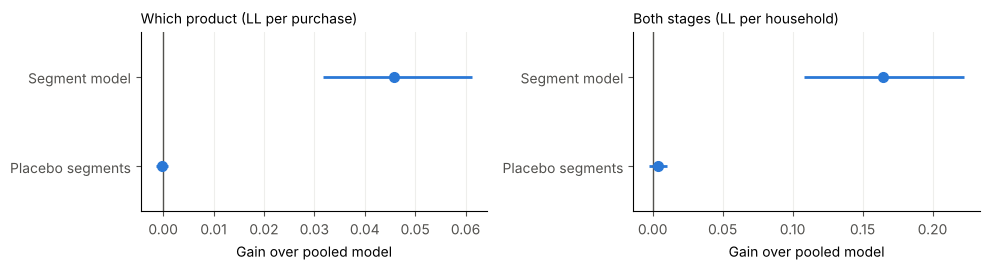

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for ax, m, title in zip(axes, ["choice", "total"], ["Which product (LL per purchase)", "Both stages (LL per household)"]):
    d = gains[gains.measure == f"gain in {labels[m]}"].set_index("model").loc[["segment", "placebo"]]
    y = np.arange(len(d))
    ax.errorbar(d.gain_vs_pooled, y, xerr=[d.gain_vs_pooled - d.ci95_low, d.ci95_high - d.gain_vs_pooled],
                fmt="o", color="#2a78d6", ms=7, elinewidth=2, capsize=0)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(y, ["Segment model", "Placebo segments"]); ax.set_ylim(len(d) - 0.5, -0.5)
    ax.set_title(title, fontsize=10, loc="left"); ax.set_xlabel("Gain over pooled model")
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    ax.grid(axis="x", color="#eeeeec"); ax.tick_params(colors="#52514e")
fig.tight_layout(); fig.savefig(OUT / "rq1_gain_over_pooled.png", dpi=150); plt.show()

## 7. Save outputs

In [8]:
table1.to_csv(OUT / "table1_holdout_performance.csv")
gains.to_csv(OUT / "rq1_bootstrap_gains.csv", index=False)
by_seg.to_csv(OUT / "within_category_fit_by_segment.csv")
pd.concat({n: o for n, o in S.items()}, names=["model", "row"]).to_parquet(OUT / "holdout_scores_per_occasion.parquet")
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  holdout_scores_per_occasion.parquet
  rq1_bootstrap_gains.csv
  rq1_gain_over_pooled.png
  table1_holdout_performance.csv
  within_category_fit_by_segment.csv


## 8. Reading the result

Write up whatever the tables show, using these pre-set rules:

- **Segments help** if the segment model's interval lies above zero **and** the placebo's interval includes zero.
- **Segments do not help** if the segment model's interval includes zero.
- If the placebo also improves on the pooled model, extra parameters alone explain part of the gain; report the segment model's gain beyond the placebo.

Do not change the models in notebook 04 after reading these results.